<a href="https://colab.research.google.com/github/MarkowitzMx/Programacion-para-analitica-descriptiva-y-predictiva-2026/blob/main/PracticaRegresionLinealMultiple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Octubre 2026
## Práctica: Práctica: Regresión Lineal Múltiple
---


## Datos del Estudiante

*   Apellidos y Nombre: Lemus Rendon Cristobal
*   Matrícula: 274690

---



##  Objetivo de aprendizaje
Al finalizar esta práctica, el estudiante será capaz de **aplicar regresión lineal múltiple utilizando Scikit-Learn para modelar la relación entre varias variables independientes y una variable dependiente**, verificar los supuestos del modelo, interpretar los coeficientes, analizar la correlación entre predictores y evaluar el rendimiento del modelo utilizando métricas como el MSE, RMSE y R².

Datos
Trabajarás con el archivo `advertising.csv`, que contiene información sobre el gasto publicitario en diferentes medios y las ventas obtenidas:

-`TV`: inversión en publicidad televisiva.

-`Radio`: inversión en publicidad en radio.

-`Newspaper`: inversión en publicidad en periódicos.

`Sales`: ventas del producto (variable dependiente).

## Parte 1: Carga de datos y bibliotecas
1. Importa las bibliotecas necesarias.
2. Carga el archivo `advertising.csv`.
3. Muestra las primeras filas del dataframe.
4. Describe estadísticamente las variables.

In [1]:
# Importamos os para verificar si existe el archivo en una ruta
import os
# Importamos pandas para manipular tablas (DataFrames)
import pandas as pd
# Importamos numpy para operaciones numéricas
import numpy as np
# Importamos matplotlib para crear gráficos
import matplotlib.pyplot as plt
# Importamos seaborn para gráficos estadísticos (heatmap, regplot, histplot)
import seaborn as sns
# Importamos el módulo de estadística de scipy (pruebas de normalidad, asimetría)
from scipy import stats
# Importamos la regresión lineal de Scikit-Learn
from sklearn.linear_model import LinearRegression
# Importamos las métricas de evaluación (MSE y R²)
from sklearn.metrics import mean_squared_error, r2_score
# Importamos statsmodels para obtener el resumen estadístico con p-values
import statsmodels.api as sm
# Importamos el cálculo del VIF (Variance Inflation Factor)
from statsmodels.stats.outliers_influence import variance_inflation_factor
# Importamos la prueba de Breusch-Pagan para verificar homocedasticidad
from statsmodels.stats.diagnostic import het_breuschpagan

# Definimos un estilo visual limpio para todos los gráficos
sns.set_theme(style="whitegrid")

# Ruta del archivo dentro de Colab (carpeta sample_data)
ruta = 'sample_data/advertising.csv'
# Si esa ruta no existe (por ejemplo, al ejecutar fuera de Colab) usamos la carpeta actual
if not os.path.exists(ruta):
    # Ruta alternativa: el archivo junto al notebook
    ruta = 'advertising.csv'
# Cargamos el archivo CSV en un DataFrame
df = pd.read_csv(ruta)

# Mostramos las primeras 5 filas del DataFrame
print("Primeras filas del dataframe:")
# display muestra la tabla con formato en el notebook
display(df.head())

# Mostramos las dimensiones (filas, columnas) del dataset
print("Dimensiones (filas, columnas):", df.shape)
# Revisamos el número de valores nulos por columna
print("\nValores nulos por columna:")
# isnull().sum() cuenta los nulos de cada columna
print(df.isnull().sum())

# Descripción estadística de las variables (media, desviación, cuartiles, min y max)
print("\nDescripción estadística:")
# round(3) limita los resultados a 3 decimales para leerlos mejor
display(df.describe().round(3))

Primeras filas del dataframe:


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


Dimensiones (filas, columnas): (200, 4)

Valores nulos por columna:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Descripción estadística:


,TV,Radio,Newspaper,Sales
count,200.000,200.000,200.000,200.000
mean,147.042,23.264,30.554,15.131
std,85.854,14.847,21.779,5.284
min,0.700,0.000,0.300,1.600
25%,74.375,9.975,12.750,11.000
50%,149.750,22.900,25.750,16.000
75%,218.825,36.525,45.100,19.050
max,296.400,49.600,114.000,27.000


**Interpretación Parte 1.** El dataset tiene **200 observaciones y 4 columnas**, sin valores nulos. La inversión media es de ≈147 en TV, ≈23.3 en Radio y ≈30.6 en Periódico; las ventas promedian ≈15.1 (rango de 1.6 a 27). Newspaper tiene el valor máximo más alejado de su mediana (114 vs. 25.75), lo que sugiere una distribución sesgada a la derecha.

## Parte 2: Análisis exploratorio de los datos
### 2.1  Análisis de la Relación Lineal entre la variable dependiente y las independientes
1. Grafica dispersión entre cada variable independiente (`TV`, `Radio`, `Newspaper`) y `Sales`. Usa también regplot.
2. Interpreta visualmente la relación entre variables.

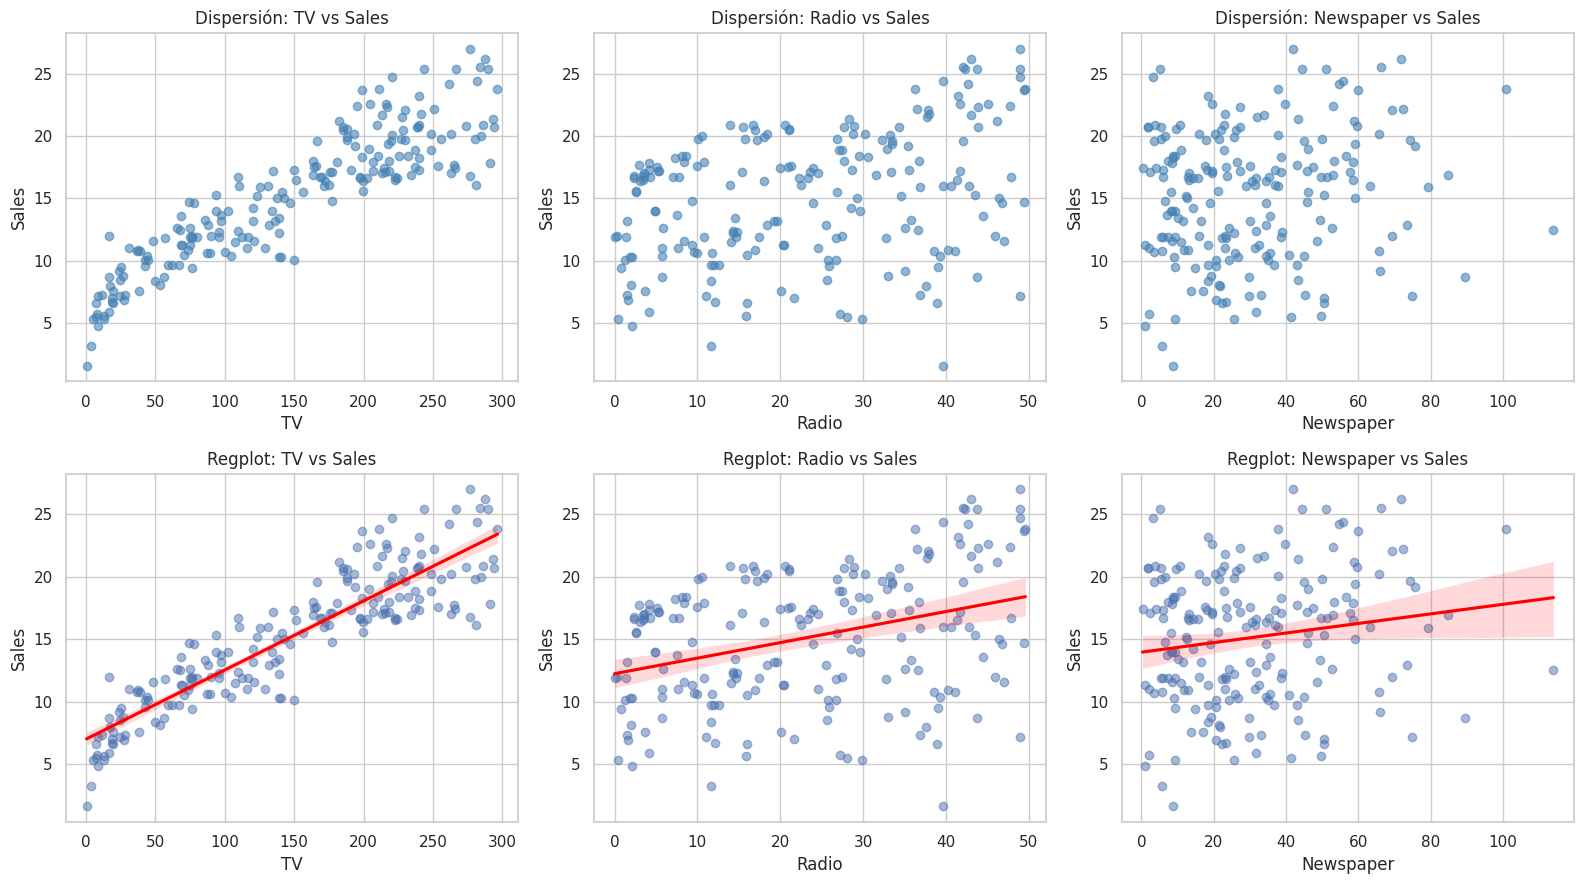

TV         -> r de Pearson = 0.901 (p-value = 7.93e-74)
Radio      -> r de Pearson = 0.350 (p-value = 3.88e-07)
Newspaper  -> r de Pearson = 0.158 (p-value = 2.55e-02)


In [2]:
# Lista con los nombres de las variables independientes (predictores)
predictores = ['TV', 'Radio', 'Newspaper']

# Creamos una figura con 2 filas y 3 columnas de gráficos
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# Recorremos cada predictor con su posición (índice i) en la cuadrícula
for i, col in enumerate(predictores):
    # Fila 1: gráfico de dispersión simple entre el predictor y Sales
    axes[0, i].scatter(df[col], df['Sales'], alpha=0.6, color='steelblue')
    # Título del gráfico de dispersión
    axes[0, i].set_title(f'Dispersión: {col} vs Sales')
    # Etiqueta del eje X
    axes[0, i].set_xlabel(col)
    # Etiqueta del eje Y
    axes[0, i].set_ylabel('Sales')
    # Fila 2: regplot dibuja los puntos y la recta de regresión con su intervalo de confianza
    sns.regplot(x=col, y='Sales', data=df, ax=axes[1, i],
                scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
    # Título del regplot
    axes[1, i].set_title(f'Regplot: {col} vs Sales')

# Ajustamos los espacios entre gráficos para que no se encimen
plt.tight_layout()
# Mostramos la figura
plt.show()

# Cuantificamos la relación lineal con el coeficiente de Pearson de cada predictor
for col in predictores:
    # pearsonr devuelve (coeficiente r, p-value)
    r, p = stats.pearsonr(df[col], df['Sales'])
    # Imprimimos r y p-value con 3 decimales
    print(f"{col:10s} -> r de Pearson = {r:.3f} (p-value = {p:.2e})")

**Interpretación 2.1.**
- **TV:** relación lineal **positiva y muy fuerte** (r ≈ 0.90). Los puntos se agrupan estrechamente alrededor de la recta; a mayor inversión en TV, mayores ventas.
- **Radio:** relación lineal **positiva y moderada** (r ≈ 0.35). Se aprecia tendencia ascendente pero con mucha dispersión alrededor de la recta.
- **Newspaper:** relación **muy débil** (r ≈ 0.16). La recta es casi plana y los puntos forman una nube dispersa: prácticamente **no hay relación lineal útil** con las ventas.

### 2.2: Correlación entre variables
1. Calcula la matriz de correlación.
2. Visualízala con un heatmap.
3. Responde: ¿Qué variables están más correlacionadas con `Sales`? ¿Hay correlación alta entre predictores?

,TV,Radio,Newspaper,Sales
TV,1.000,0.055,0.057,0.901
Radio,0.055,1.000,0.354,0.350
Newspaper,0.057,0.354,1.000,0.158
Sales,0.901,0.350,0.158,1.000


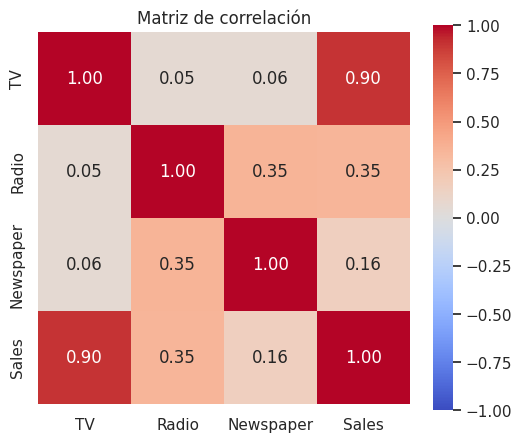

Correlación con Sales (de mayor a menor):
TV           0.901
Radio        0.350
Newspaper    0.158
Name: Sales, dtype: float64


In [3]:
# Calculamos la matriz de correlación de Pearson entre todas las variables
matriz_corr = df.corr()
# Mostramos la matriz con 3 decimales
display(matriz_corr.round(3))

# Creamos la figura para el mapa de calor
plt.figure(figsize=(6, 5))
# heatmap: annot muestra los valores, cmap define la paleta, vmin/vmax fijan la escala -1 a 1
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
# Título del mapa de calor
plt.title('Matriz de correlación')
# Mostramos el gráfico
plt.show()

# Ordenamos las correlaciones con Sales (excluyendo a Sales consigo misma)
print("Correlación con Sales (de mayor a menor):")
# drop('Sales') quita la autocorrelación y sort_values ordena de mayor a menor
print(matriz_corr['Sales'].drop('Sales').sort_values(ascending=False).round(3))

**Respuestas 2.2.**
- **¿Qué variable está más correlacionada con Sales?** **TV** (r = 0.90), seguida de Radio (0.35) y Newspaper (0.16).
- **¿Hay correlación alta entre predictores?** **No.** La más alta es Radio–Newspaper (r = 0.35, moderada-baja); TV–Radio (0.055) y TV–Newspaper (0.057) son casi nulas. Los predictores aportan información prácticamente independiente.

## Parte 3. Multicolinealidad
1. Calcula el VIF (Variance Inflation Factor) para cada predictor.
2. Crea un diagrama de barras  para mostrar el  VIF
3. Interpreta si hay multicolinealidad:
- ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?
- ¿Qué implicaciones tiene esto para el modelo?

,Variable,VIF
0,TV,1.005
1,Radio,1.145
2,Newspaper,1.145


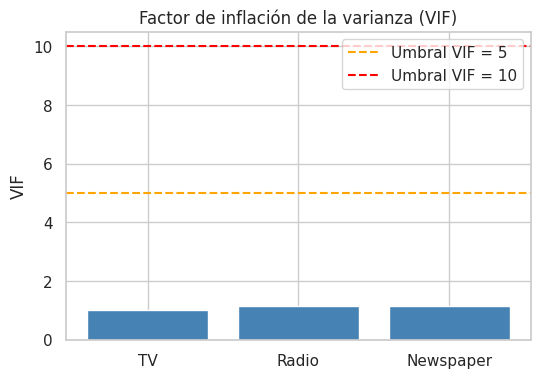

In [4]:
# Construimos la matriz de predictores añadiendo la columna constante (intercepto) que exige el cálculo del VIF
X_vif = sm.add_constant(df[['TV', 'Radio', 'Newspaper']])

# Creamos un DataFrame para guardar el VIF de cada variable
vif_df = pd.DataFrame()
# Guardamos los nombres de los predictores (omitimos la constante, que es la columna 0)
vif_df['Variable'] = X_vif.columns[1:]
# Calculamos el VIF de cada predictor (i empieza en 1 para saltar la constante)
vif_df['VIF'] = [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])]
# Mostramos la tabla de VIF
display(vif_df.round(3))

# Creamos la figura del diagrama de barras
plt.figure(figsize=(6, 4))
# Dibujamos una barra por variable con su VIF
plt.bar(vif_df['Variable'], vif_df['VIF'], color='steelblue')
# Línea de referencia en VIF = 5 (multicolinealidad moderada)
plt.axhline(5, color='orange', linestyle='--', label='Umbral VIF = 5')
# Línea de referencia en VIF = 10 (multicolinealidad severa)
plt.axhline(10, color='red', linestyle='--', label='Umbral VIF = 10')
# Título del gráfico
plt.title('Factor de inflación de la varianza (VIF)')
# Etiqueta del eje Y
plt.ylabel('VIF')
# Mostramos la leyenda con los umbrales
plt.legend()
# Mostramos el gráfico
plt.show()

**Interpretación Parte 3.**
- **¿Alguna variable tiene VIF > 5 o > 10?** **No.** Los VIF son ≈1.00 (TV), ≈1.14 (Radio) y ≈1.14 (Newspaper), todos muy cerca de 1 (el mínimo posible).
- **Implicaciones:** **no existe multicolinealidad**. Los coeficientes del modelo son estables y sus errores estándar no se inflan, por lo que se pueden interpretar de forma individual con confianza. Esto concuerda con las bajas correlaciones entre predictores de la sección 2.2.

## Parte 4: Construcción del Modelo (Todas las variables Independientes), Evaluación

### 4.1 Entrenamiento del Modelo (Todas las Variables Independientes)

1. Entrena un modelo de regresión lineal múltiple usando TV, Radio y Newspaper como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [5]:
# Seleccionamos las columnas predictoras de este modelo
cols_p4 = ['TV', 'Radio', 'Newspaper']
# Matriz de variables independientes X
X_p4 = df[cols_p4]
# Variable dependiente y (ventas)
y = df['Sales']

# Creamos el modelo de regresión lineal múltiple
modelo_p4 = LinearRegression()
# Entrenamos el modelo con los datos (estima el intercepto y los coeficientes)
modelo_p4.fit(X_p4, y)

# Imprimimos el intercepto (β0): ventas esperadas cuando todos los predictores valen 0
print(f"Intercepto (β0): {modelo_p4.intercept_:.4f}")
# Recorremos cada predictor junto con su coeficiente estimado
for nombre, coef in zip(X_p4.columns, modelo_p4.coef_):
    # Imprimimos el coeficiente (β) de cada variable
    print(f"Coeficiente de {nombre}: {coef:.4f}")

Intercepto (β0): 4.6251
Coeficiente de TV: 0.0544
Coeficiente de Radio: 0.1070
Coeficiente de Newspaper: 0.0003


**Interpretación 4.1.** Modelo: Sales = 4.625 + 0.0544·TV + 0.1070·Radio + 0.0003·Newspaper.
- **Intercepto (≈4.63):** ventas esperadas sin inversión en ningún medio.
- **TV (≈0.0544):** manteniendo Radio y Newspaper constantes, cada unidad adicional invertida en TV se asocia con ≈0.054 unidades más de ventas.
- **Radio (≈0.1070):** manteniendo los demás constantes, cada unidad adicional en Radio se asocia con ≈0.107 unidades más de ventas (efecto por unidad ~2 veces el de TV).
- **Newspaper (≈0.0003):** prácticamente **cero**; una unidad más en periódico casi no cambia las ventas una vez que se controlan TV y Radio.

### 4.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

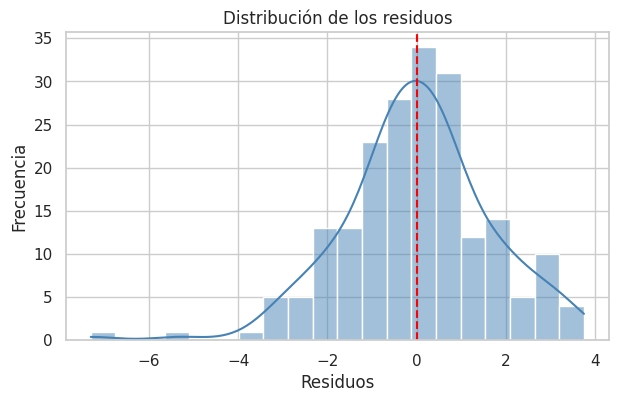

Shapiro-Wilk: estadístico = 0.9758, p-value = 0.0016
Asimetría (skew) = -0.431


In [6]:
# Obtenemos las ventas predichas por el modelo para cada observación
y_pred_p4 = modelo_p4.predict(X_p4)
# Calculamos los residuos: valor real menos valor predicho
residuos_p4 = y - y_pred_p4

# Creamos la figura del histograma
plt.figure(figsize=(7, 4))
# Histograma de los residuos con la curva KDE (densidad estimada) superpuesta
sns.histplot(residuos_p4, kde=True, bins=20, color='steelblue')
# Línea vertical en 0 como referencia (residuo ideal)
plt.axvline(0, color='red', linestyle='--')
# Título del gráfico
plt.title('Distribución de los residuos')
# Etiqueta del eje X
plt.xlabel('Residuos')
# Etiqueta del eje Y
plt.ylabel('Frecuencia')
# Mostramos el gráfico
plt.show()

# Prueba de Shapiro-Wilk: H0 = los residuos son normales
est_sw, p_sw = stats.shapiro(residuos_p4)
# Imprimimos el resultado de la prueba
print(f"Shapiro-Wilk: estadístico = {est_sw:.4f}, p-value = {p_sw:.4f}")
# Imprimimos la asimetría (0 = simétrica; negativa = cola larga a la izquierda)
print(f"Asimetría (skew) = {stats.skew(residuos_p4):.3f}")

**Interpretación 4.2.** El histograma está centrado cerca de 0 pero es **asimétrico a la izquierda** (skew ≈ −0.43) con una cola de residuos muy negativos (hasta ≈ −7.3). La prueba de Shapiro-Wilk (p ≈ 0.0016 < 0.05) **rechaza la normalidad estricta**. Aun así, la desviación es moderada y con 200 datos la inferencia sigue siendo razonablemente robusta.

### 4.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

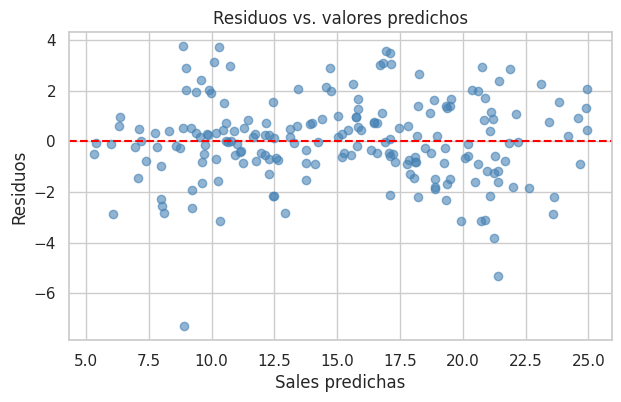

Breusch-Pagan: p-value = 0.2638


In [7]:
# Creamos la figura para el gráfico de residuos vs. predichos
plt.figure(figsize=(7, 4))
# Cada punto es una observación: eje X = valor predicho, eje Y = residuo
plt.scatter(y_pred_p4, residuos_p4, alpha=0.6, color='steelblue')
# Línea horizontal en 0 (los residuos deberían repartirse alrededor de ella)
plt.axhline(0, color='red', linestyle='--')
# Título del gráfico
plt.title('Residuos vs. valores predichos')
# Etiqueta del eje X
plt.xlabel('Sales predichas')
# Etiqueta del eje Y
plt.ylabel('Residuos')
# Mostramos el gráfico
plt.show()

# Prueba de Breusch-Pagan: H0 = varianza constante (homocedasticidad)
bp = het_breuschpagan(residuos_p4, sm.add_constant(X_p4))
# bp[1] es el p-value del estadístico LM; lo imprimimos
print(f"Breusch-Pagan: p-value = {bp[1]:.4f}")

**Interpretación 4.3.** Los residuos se reparten de forma aleatoria alrededor de 0, sin forma de embudo. La prueba de Breusch-Pagan (H0: varianza constante) da p ≈ 0.26 > 0.05, por lo que no se rechaza H0: **se cumple el supuesto de homocedasticidad**. Sin embargo, se aprecia una **ligera curvatura** (residuos positivos en el centro y negativos en los extremos), señal de una pequeña no linealidad (posible efecto de interacción TV×Radio) que el modelo lineal no captura.

### 4.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

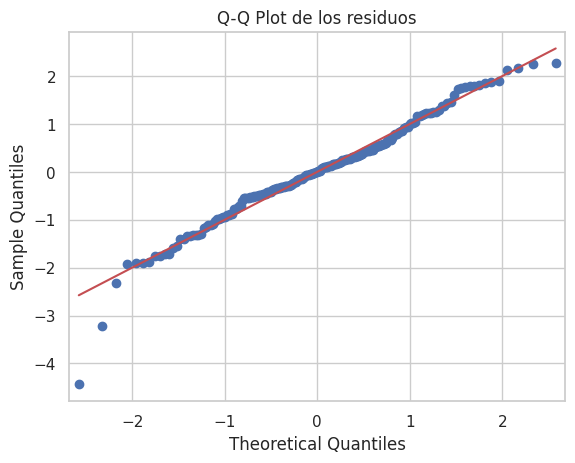

In [8]:
# Creamos el Q-Q plot de los residuos contra una distribución normal teórica
fig = sm.qqplot(residuos_p4, line='s', fit=True)
# Título del gráfico
plt.title('Q-Q Plot de los residuos')
# Mostramos el gráfico
plt.show()

**Interpretación 4.4.** Los puntos siguen la diagonal en la zona central, pero **se separan en la cola izquierda** (residuos muy negativos). Esto indica **asimetría negativa / cola pesada a la izquierda**, coherente con la prueba de Shapiro-Wilk. La normalidad se cumple de forma aproximada, no exacta.

### 4.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?


In [9]:
# MSE: promedio de los errores elevados al cuadrado
mse_p4 = mean_squared_error(y, y_pred_p4)
# RMSE: raíz del MSE, queda en las mismas unidades que Sales
rmse_p4 = np.sqrt(mse_p4)
# R²: proporción de la varianza de Sales explicada por el modelo
r2_p4 = r2_score(y, y_pred_p4)

# Imprimimos el MSE
print(f"MSE  = {mse_p4:.4f}")
# Imprimimos el RMSE
print(f"RMSE = {rmse_p4:.4f}")
# Imprimimos el R²
print(f"R²   = {r2_p4:.4f}")

MSE  = 2.7060
RMSE = 1.6450
R²   = 0.9026


**Interpretación 4.5.** MSE ≈ 2.71, RMSE ≈ 1.65 y **R² ≈ 0.903**. El modelo explica ≈90 % de la variabilidad de las ventas, y en promedio se equivoca ≈1.65 unidades (frente a una desviación estándar de Sales de ≈5.28). Es un **ajuste muy bueno**. (Nota: se evalúa sobre los mismos datos con que se entrenó, tal como pide la práctica.)

### 4.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.
3.¿Qué observas?¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

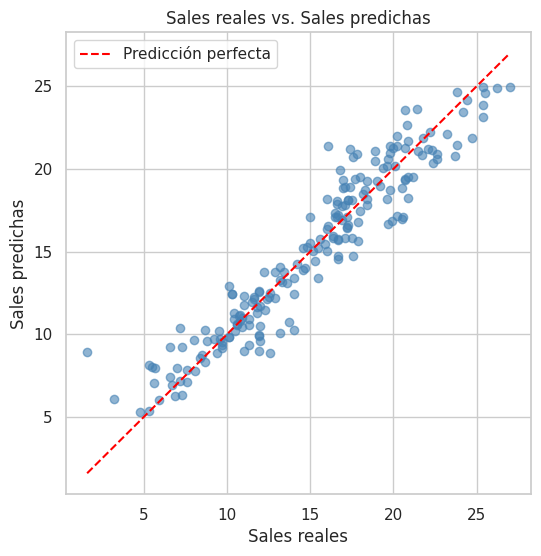

In [10]:
# Creamos la figura
plt.figure(figsize=(6, 6))
# Dispersión de ventas reales (X) contra ventas predichas (Y)
plt.scatter(y, y_pred_p4, alpha=0.6, color='steelblue')
# Calculamos los límites mínimo y máximo para trazar la diagonal
lim = [y.min(), y.max()]
# Línea diagonal y = x: si el modelo fuera perfecto todos los puntos caerían sobre ella
plt.plot(lim, lim, color='red', linestyle='--', label='Predicción perfecta')
# Etiqueta del eje X
plt.xlabel('Sales reales')
# Etiqueta del eje Y
plt.ylabel('Sales predichas')
# Título del gráfico
plt.title('Sales reales vs. Sales predichas')
# Mostramos la leyenda
plt.legend()
# Mostramos el gráfico
plt.show()

**Interpretación 4.6.** Los puntos se concentran cerca de la diagonal, lo que confirma el buen ajuste. Se ven algunas observaciones con ventas reales claramente **por debajo** de lo predicho (las de residuo muy negativo) y una ligera curvatura: el modelo tiende a sobrestimar en ventas bajas y subestimar en el rango medio. La gráfica permite ver rápidamente dónde falla el modelo.

### 4.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?


In [11]:
# Añadimos la columna constante (intercepto), que statsmodels no incluye por defecto
X_sm_p4 = sm.add_constant(X_p4)
# Ajustamos el modelo de mínimos cuadrados ordinarios (OLS)
ols_p4 = sm.OLS(y, X_sm_p4).fit()
# Imprimimos el resumen completo (coeficientes, errores estándar, t, P>|t|, R², etc.)
print(ols_p4.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           8.13e-99
Time:                        02:07:55   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6251      0.308     15.041      0.0

**Interpretación 4.7.**
- **p-value < 0.05:** **TV** (p ≈ 0.000) y **Radio** (p ≈ 0.000), además del intercepto.
- **Newspaper** tiene p ≈ **0.954** (> 0.05) y su intervalo de confianza [−0.011, 0.012] contiene el 0.
- **Conclusión:** TV y Radio tienen un efecto estadísticamente significativo sobre las ventas; **Newspaper no aporta** información significativa una vez incluidas TV y Radio, por lo que es candidato a eliminarse.

##Parte 5:  Construcción del Modelo (sin Multicolinealidad), Evaluación

En el caso de que hayas detectado variables con multicolinealidad. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

In [12]:
# Partimos de la lista completa de predictores
predictores_p5 = ['TV', 'Radio', 'Newspaper']
# Guardamos las variables que se eliminen por multicolinealidad
eliminadas = []

# Repetimos hasta que ningún predictor tenga VIF mayor a 5
while True:
    # Añadimos la constante a los predictores actuales
    X_tmp = sm.add_constant(df[predictores_p5])
    # Calculamos el VIF de cada predictor actual (saltando la constante)
    vifs = pd.Series([variance_inflation_factor(X_tmp.values, i + 1) for i in range(len(predictores_p5))],
                     index=predictores_p5)
    # Si el VIF más alto supera 5, hay multicolinealidad
    if vifs.max() > 5:
        # Identificamos la variable con mayor VIF
        peor = vifs.idxmax()
        # La quitamos de la lista de predictores
        predictores_p5.remove(peor)
        # Registramos que fue eliminada
        eliminadas.append(peor)
    # Si ningún VIF supera 5, terminamos el filtrado
    else:
        break

# Mostramos los VIF finales
print("VIF finales:\n", vifs.round(3))
# Mostramos las variables eliminadas (lista vacía si no hubo multicolinealidad)
print("\nVariables eliminadas por multicolinealidad:", eliminadas if eliminadas else "ninguna")
# Mostramos los predictores que se conservan
print("Predictores conservados:", predictores_p5)

VIF finales:
 TV           1.005
Radio        1.145
Newspaper    1.145
dtype: float64

Variables eliminadas por multicolinealidad: ninguna
Predictores conservados: ['TV', 'Radio', 'Newspaper']


**Resultado del filtrado.** En la Parte 3 ningún VIF superó 5 (ni 10), por lo que **no se elimina ninguna variable por multicolinealidad**. En consecuencia, el modelo de la Parte 5 usa los mismos tres predictores y **es idéntico al de la Parte 4**. Se repiten los pasos a continuación (como pide la práctica) para dejar documentada esta equivalencia.

### 5.1 Entrenamiento del Modelo

1. Entrena un modelo de regresión lineal múltiple sin usar las variables que presentaban multicolinealidad.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [13]:
# Seleccionamos las columnas predictoras de este modelo
cols_p5 = predictores_p5
# Matriz de variables independientes X
X_p5 = df[cols_p5]
# Variable dependiente y (ventas)
y = df['Sales']

# Creamos el modelo de regresión lineal múltiple
modelo_p5 = LinearRegression()
# Entrenamos el modelo con los datos (estima el intercepto y los coeficientes)
modelo_p5.fit(X_p5, y)

# Imprimimos el intercepto (β0): ventas esperadas cuando todos los predictores valen 0
print(f"Intercepto (β0): {modelo_p5.intercept_:.4f}")
# Recorremos cada predictor junto con su coeficiente estimado
for nombre, coef in zip(X_p5.columns, modelo_p5.coef_):
    # Imprimimos el coeficiente (β) de cada variable
    print(f"Coeficiente de {nombre}: {coef:.4f}")

Intercepto (β0): 4.6251
Coeficiente de TV: 0.0544
Coeficiente de Radio: 0.1070
Coeficiente de Newspaper: 0.0003


**Interpretación 5.1.** Al no eliminarse variables, el intercepto (≈4.625) y los coeficientes (TV ≈ 0.0544, Radio ≈ 0.1070, Newspaper ≈ 0.0003) son **exactamente los mismos que en la Parte 4**, con la misma interpretación: TV y Radio aumentan las ventas; Newspaper tiene un efecto prácticamente nulo.

### 5.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

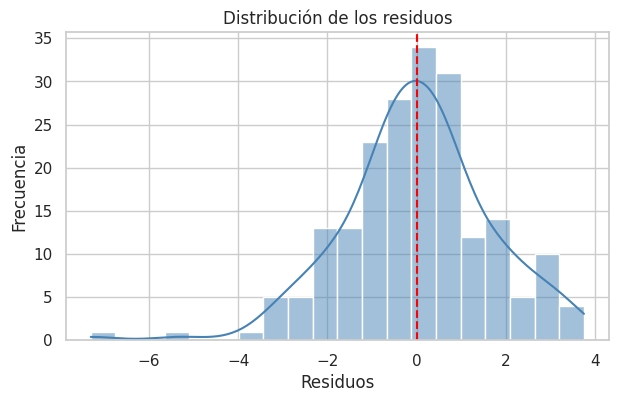

Shapiro-Wilk: estadístico = 0.9758, p-value = 0.0016
Asimetría (skew) = -0.431


In [14]:
# Obtenemos las ventas predichas por el modelo para cada observación
y_pred_p5 = modelo_p5.predict(X_p5)
# Calculamos los residuos: valor real menos valor predicho
residuos_p5 = y - y_pred_p5

# Creamos la figura del histograma
plt.figure(figsize=(7, 4))
# Histograma de los residuos con la curva KDE (densidad estimada) superpuesta
sns.histplot(residuos_p5, kde=True, bins=20, color='steelblue')
# Línea vertical en 0 como referencia (residuo ideal)
plt.axvline(0, color='red', linestyle='--')
# Título del gráfico
plt.title('Distribución de los residuos')
# Etiqueta del eje X
plt.xlabel('Residuos')
# Etiqueta del eje Y
plt.ylabel('Frecuencia')
# Mostramos el gráfico
plt.show()

# Prueba de Shapiro-Wilk: H0 = los residuos son normales
est_sw, p_sw = stats.shapiro(residuos_p5)
# Imprimimos el resultado de la prueba
print(f"Shapiro-Wilk: estadístico = {est_sw:.4f}, p-value = {p_sw:.4f}")
# Imprimimos la asimetría (0 = simétrica; negativa = cola larga a la izquierda)
print(f"Asimetría (skew) = {stats.skew(residuos_p5):.3f}")

**Interpretación 5.2.** Idéntica a la Parte 4: residuos con asimetría negativa (≈ −0.43) y Shapiro-Wilk p ≈ 0.0016, es decir, **normalidad aproximada pero no estricta**.

### 5.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

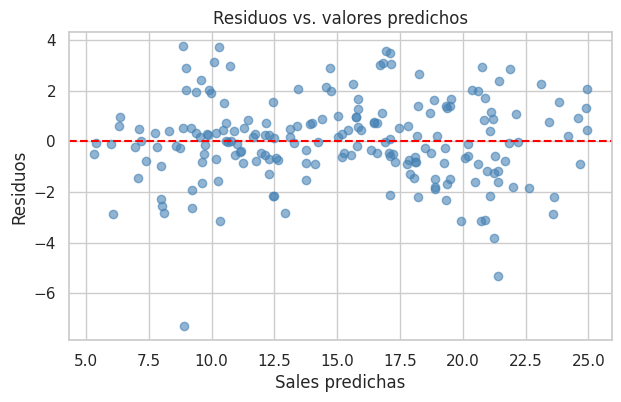

Breusch-Pagan: p-value = 0.2638


In [15]:
# Creamos la figura para el gráfico de residuos vs. predichos
plt.figure(figsize=(7, 4))
# Cada punto es una observación: eje X = valor predicho, eje Y = residuo
plt.scatter(y_pred_p5, residuos_p5, alpha=0.6, color='steelblue')
# Línea horizontal en 0 (los residuos deberían repartirse alrededor de ella)
plt.axhline(0, color='red', linestyle='--')
# Título del gráfico
plt.title('Residuos vs. valores predichos')
# Etiqueta del eje X
plt.xlabel('Sales predichas')
# Etiqueta del eje Y
plt.ylabel('Residuos')
# Mostramos el gráfico
plt.show()

# Prueba de Breusch-Pagan: H0 = varianza constante (homocedasticidad)
bp = het_breuschpagan(residuos_p5, sm.add_constant(X_p5))
# bp[1] es el p-value del estadístico LM; lo imprimimos
print(f"Breusch-Pagan: p-value = {bp[1]:.4f}")

**Interpretación 5.3.** Igual que en la Parte 4: sin forma de embudo (Breusch-Pagan p ≈ 0.26 > 0.05) y con una ligera curvatura. **Se cumple el supuesto de homocedasticidad.**

### 5.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

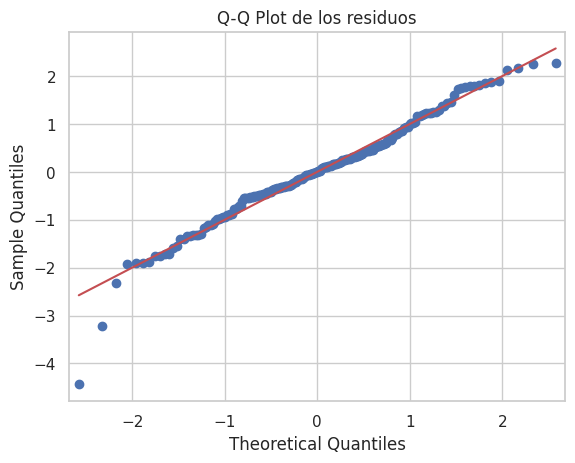

In [16]:
# Creamos el Q-Q plot de los residuos contra una distribución normal teórica
fig = sm.qqplot(residuos_p5, line='s', fit=True)
# Título del gráfico
plt.title('Q-Q Plot de los residuos')
# Mostramos el gráfico
plt.show()

**Interpretación 5.4.** El Q-Q plot es el mismo: ajuste a la diagonal en el centro y desviación en la cola izquierda (asimetría negativa).

### 5.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?

In [17]:
# MSE: promedio de los errores elevados al cuadrado
mse_p5 = mean_squared_error(y, y_pred_p5)
# RMSE: raíz del MSE, queda en las mismas unidades que Sales
rmse_p5 = np.sqrt(mse_p5)
# R²: proporción de la varianza de Sales explicada por el modelo
r2_p5 = r2_score(y, y_pred_p5)

# Imprimimos el MSE
print(f"MSE  = {mse_p5:.4f}")
# Imprimimos el RMSE
print(f"RMSE = {rmse_p5:.4f}")
# Imprimimos el R²
print(f"R²   = {r2_p5:.4f}")

MSE  = 2.7060
RMSE = 1.6450
R²   = 0.9026


**Interpretación 5.5.** MSE ≈ 2.71, RMSE ≈ 1.65, R² ≈ 0.903; **métricas idénticas a las de la Parte 4**, como era de esperar al ser el mismo modelo.

### 5.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.
3. ¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

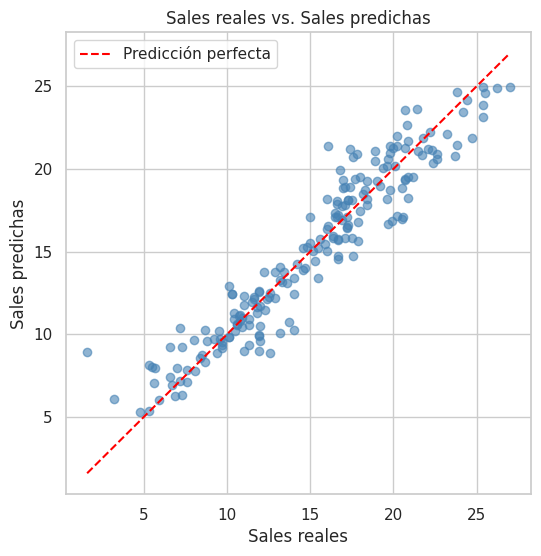

In [18]:
# Creamos la figura
plt.figure(figsize=(6, 6))
# Dispersión de ventas reales (X) contra ventas predichas (Y)
plt.scatter(y, y_pred_p5, alpha=0.6, color='steelblue')
# Calculamos los límites mínimo y máximo para trazar la diagonal
lim = [y.min(), y.max()]
# Línea diagonal y = x: si el modelo fuera perfecto todos los puntos caerían sobre ella
plt.plot(lim, lim, color='red', linestyle='--', label='Predicción perfecta')
# Etiqueta del eje X
plt.xlabel('Sales reales')
# Etiqueta del eje Y
plt.ylabel('Sales predichas')
# Título del gráfico
plt.title('Sales reales vs. Sales predichas')
# Mostramos la leyenda
plt.legend()
# Mostramos el gráfico
plt.show()

**Interpretación 5.6.** Gráfica idéntica a la 4.6: buen ajuste general alrededor de la diagonal, con algunas ventas reales por debajo de lo predicho.

### 5.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?

In [19]:
# Añadimos la columna constante (intercepto), que statsmodels no incluye por defecto
X_sm_p5 = sm.add_constant(X_p5)
# Ajustamos el modelo de mínimos cuadrados ordinarios (OLS)
ols_p5 = sm.OLS(y, X_sm_p5).fit()
# Imprimimos el resumen completo (coeficientes, errores estándar, t, P>|t|, R², etc.)
print(ols_p5.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           8.13e-99
Time:                        02:07:56   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6251      0.308     15.041      0.0

**Interpretación 5.7.** Mismos resultados que 4.7: TV y Radio son significativas (p < 0.05) y Newspaper no (p ≈ 0.954). Como no había multicolinealidad, **eliminar variables por este criterio no cambia nada**; la depuración útil viene en la Parte 6.

## Parte 6: Construcción del Modelo (sin variables que no muestran una relación lineal), Evaluación

En el caso de que hayas detectado variables sin una relación lineal con la variable dependiente. Elimina aquellas que presenten esta característica y realiza lo siguiente.

En el caso de que hayas detectado variables sin una relación lineal. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

**Variable sin relación lineal.** En la sección 2.1 la dispersión y el regplot de **Newspaper** muestran una recta casi plana (r ≈ 0.16), y en la Parte 4.7 su coeficiente no es significativo (p ≈ 0.954). Por tanto, se **elimina Newspaper** y el modelo de la Parte 6 usa solo **TV y Radio**.

### 6.1 Entrenamiento del Modelo

1. Entrena un modelo de regresión lineal múltiple sin usar las variables que no muestran una relación lineal.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [20]:
# Seleccionamos las columnas predictoras de este modelo
cols_p6 = ['TV', 'Radio']
# Matriz de variables independientes X
X_p6 = df[cols_p6]
# Variable dependiente y (ventas)
y = df['Sales']

# Creamos el modelo de regresión lineal múltiple
modelo_p6 = LinearRegression()
# Entrenamos el modelo con los datos (estima el intercepto y los coeficientes)
modelo_p6.fit(X_p6, y)

# Imprimimos el intercepto (β0): ventas esperadas cuando todos los predictores valen 0
print(f"Intercepto (β0): {modelo_p6.intercept_:.4f}")
# Recorremos cada predictor junto con su coeficiente estimado
for nombre, coef in zip(X_p6.columns, modelo_p6.coef_):
    # Imprimimos el coeficiente (β) de cada variable
    print(f"Coeficiente de {nombre}: {coef:.4f}")

Intercepto (β0): 4.6309
Coeficiente de TV: 0.0544
Coeficiente de Radio: 0.1072


**Interpretación 6.1.** Modelo: Sales = 4.631 + 0.0544·TV + 0.1072·Radio.
- **Intercepto (≈4.63):** ventas esperadas sin inversión en TV ni Radio.
- **TV (≈0.0544):** con Radio constante, cada unidad extra en TV se asocia con ≈0.054 unidades más de ventas.
- **Radio (≈0.1072):** con TV constante, cada unidad extra en Radio se asocia con ≈0.107 unidades más de ventas.
Los coeficientes casi no cambian respecto a la Parte 4, lo que confirma que Newspaper no aportaba nada.

### 6.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

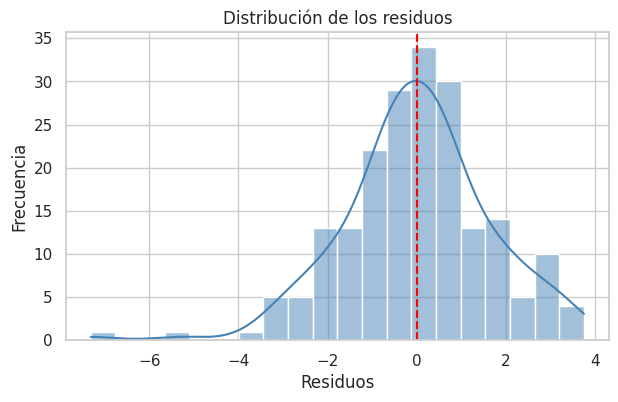

Shapiro-Wilk: estadístico = 0.9757, p-value = 0.0015
Asimetría (skew) = -0.434


In [21]:
# Obtenemos las ventas predichas por el modelo para cada observación
y_pred_p6 = modelo_p6.predict(X_p6)
# Calculamos los residuos: valor real menos valor predicho
residuos_p6 = y - y_pred_p6

# Creamos la figura del histograma
plt.figure(figsize=(7, 4))
# Histograma de los residuos con la curva KDE (densidad estimada) superpuesta
sns.histplot(residuos_p6, kde=True, bins=20, color='steelblue')
# Línea vertical en 0 como referencia (residuo ideal)
plt.axvline(0, color='red', linestyle='--')
# Título del gráfico
plt.title('Distribución de los residuos')
# Etiqueta del eje X
plt.xlabel('Residuos')
# Etiqueta del eje Y
plt.ylabel('Frecuencia')
# Mostramos el gráfico
plt.show()

# Prueba de Shapiro-Wilk: H0 = los residuos son normales
est_sw, p_sw = stats.shapiro(residuos_p6)
# Imprimimos el resultado de la prueba
print(f"Shapiro-Wilk: estadístico = {est_sw:.4f}, p-value = {p_sw:.4f}")
# Imprimimos la asimetría (0 = simétrica; negativa = cola larga a la izquierda)
print(f"Asimetría (skew) = {stats.skew(residuos_p6):.3f}")

**Interpretación 6.2.** Prácticamente igual que en la Parte 4: asimetría negativa (≈ −0.43), Shapiro-Wilk p ≈ 0.0015. La normalidad es aproximada, con cola izquierda.

### 6.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

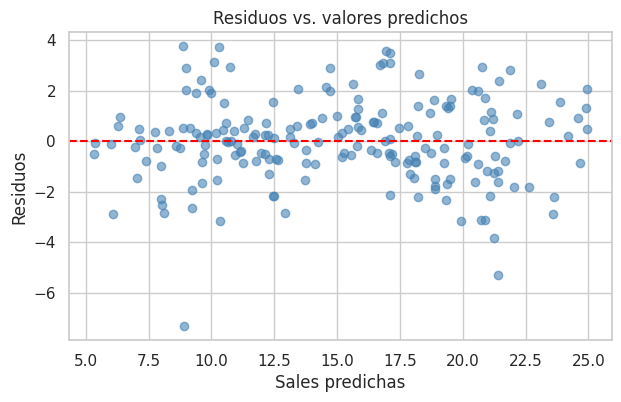

Breusch-Pagan: p-value = 0.8881


In [22]:
# Creamos la figura para el gráfico de residuos vs. predichos
plt.figure(figsize=(7, 4))
# Cada punto es una observación: eje X = valor predicho, eje Y = residuo
plt.scatter(y_pred_p6, residuos_p6, alpha=0.6, color='steelblue')
# Línea horizontal en 0 (los residuos deberían repartirse alrededor de ella)
plt.axhline(0, color='red', linestyle='--')
# Título del gráfico
plt.title('Residuos vs. valores predichos')
# Etiqueta del eje X
plt.xlabel('Sales predichas')
# Etiqueta del eje Y
plt.ylabel('Residuos')
# Mostramos el gráfico
plt.show()

# Prueba de Breusch-Pagan: H0 = varianza constante (homocedasticidad)
bp = het_breuschpagan(residuos_p6, sm.add_constant(X_p6))
# bp[1] es el p-value del estadístico LM; lo imprimimos
print(f"Breusch-Pagan: p-value = {bp[1]:.4f}")

**Interpretación 6.3.** Sin forma de embudo (Breusch-Pagan p ≈ 0.89 > 0.05, aún más claro que antes) y con la misma ligera curvatura. **Se cumple el supuesto de homocedasticidad.**

### 6.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

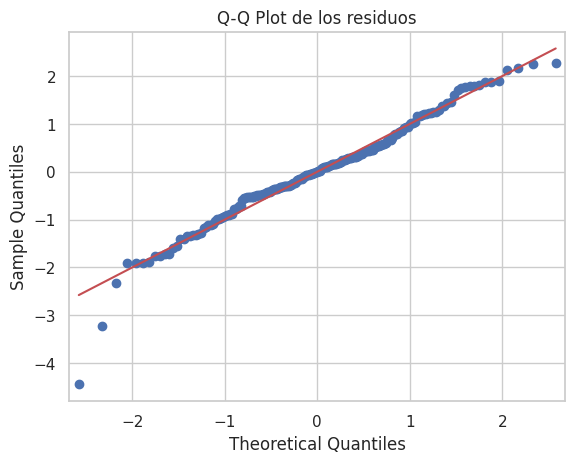

In [23]:
# Creamos el Q-Q plot de los residuos contra una distribución normal teórica
fig = sm.qqplot(residuos_p6, line='s', fit=True)
# Título del gráfico
plt.title('Q-Q Plot de los residuos')
# Mostramos el gráfico
plt.show()

**Interpretación 6.4.** Mismo comportamiento: puntos sobre la diagonal en el centro y desviación en la cola izquierda.

### 6.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?

In [24]:
# MSE: promedio de los errores elevados al cuadrado
mse_p6 = mean_squared_error(y, y_pred_p6)
# RMSE: raíz del MSE, queda en las mismas unidades que Sales
rmse_p6 = np.sqrt(mse_p6)
# R²: proporción de la varianza de Sales explicada por el modelo
r2_p6 = r2_score(y, y_pred_p6)

# Imprimimos el MSE
print(f"MSE  = {mse_p6:.4f}")
# Imprimimos el RMSE
print(f"RMSE = {rmse_p6:.4f}")
# Imprimimos el R²
print(f"R²   = {r2_p6:.4f}")

MSE  = 2.7061
RMSE = 1.6450
R²   = 0.9026


**Interpretación 6.5.** MSE ≈ 2.71, RMSE ≈ 1.65, **R² ≈ 0.903**, es decir, **se conserva el mismo poder explicativo** con una variable menos. El modelo es más simple sin perder precisión.

### 6.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.
3. ¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

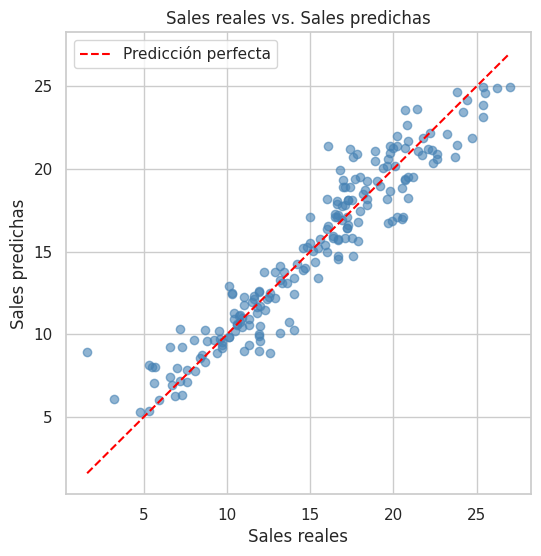

In [25]:
# Creamos la figura
plt.figure(figsize=(6, 6))
# Dispersión de ventas reales (X) contra ventas predichas (Y)
plt.scatter(y, y_pred_p6, alpha=0.6, color='steelblue')
# Calculamos los límites mínimo y máximo para trazar la diagonal
lim = [y.min(), y.max()]
# Línea diagonal y = x: si el modelo fuera perfecto todos los puntos caerían sobre ella
plt.plot(lim, lim, color='red', linestyle='--', label='Predicción perfecta')
# Etiqueta del eje X
plt.xlabel('Sales reales')
# Etiqueta del eje Y
plt.ylabel('Sales predichas')
# Título del gráfico
plt.title('Sales reales vs. Sales predichas')
# Mostramos la leyenda
plt.legend()
# Mostramos el gráfico
plt.show()

**Interpretación 6.6.** La nube de puntos sigue la diagonal igual que en los modelos anteriores; quitar Newspaper no deteriora las predicciones.

### 6.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?

In [26]:
# Añadimos la columna constante (intercepto), que statsmodels no incluye por defecto
X_sm_p6 = sm.add_constant(X_p6)
# Ajustamos el modelo de mínimos cuadrados ordinarios (OLS)
ols_p6 = sm.OLS(y, X_sm_p6).fit()
# Imprimimos el resumen completo (coeficientes, errores estándar, t, P>|t|, R², etc.)
print(ols_p6.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.902
Method:                 Least Squares   F-statistic:                     912.7
Date:                Fri, 30 Oct 2026   Prob (F-statistic):          2.39e-100
Time:                        02:07:57   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             772.7
Df Residuals:                     197   BIC:                             782.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6309      0.290     15.952      0.0

**Interpretación 6.7.** **TV y Radio tienen p ≈ 0.000 (< 0.05)**: ambas son significativas, y ya no hay ninguna variable irrelevante en el modelo. El R² ajustado sube ligeramente (≈0.9016 vs. 0.9011) y el AIC baja (≈772.7 vs. 774.7), señales de que este modelo es más parsimonioso y ligeramente mejor.

##7. Conclusiones.

¿Cuál de los tres modelos construidos fue el mejor?
¿Cuál fue el atributo que mas influencia tiene en las ventas?

In [27]:
# Diccionario con los tres modelos construidos y sus predictores
modelos = {
    'Modelo 1 (TV+Radio+Newspaper)': ['TV', 'Radio', 'Newspaper'],
    'Modelo 2 (sin multicolinealidad)': predictores_p5,
    'Modelo 3 (TV+Radio)': ['TV', 'Radio'],
}
# Lista donde guardaremos una fila de resultados por modelo
filas = []
# Recorremos cada modelo
for nombre, cols in modelos.items():
    # Ajustamos con statsmodels para obtener R² ajustado y AIC
    ols = sm.OLS(df['Sales'], sm.add_constant(df[cols])).fit()
    # Calculamos las predicciones del modelo
    pred = ols.predict(sm.add_constant(df[cols]))
    # Calculamos el MSE
    mse = mean_squared_error(df['Sales'], pred)
    # Guardamos las métricas de este modelo
    filas.append({'Modelo': nombre, 'N° variables': len(cols), 'MSE': mse, 'RMSE': np.sqrt(mse),
                  'R²': ols.rsquared, 'R² ajustado': ols.rsquared_adj, 'AIC': ols.aic})
# Convertimos la lista en tabla y la mostramos
display(pd.DataFrame(filas).round(4))

# Estandarizamos TV y Radio (media 0, desviación 1) para comparar su influencia en la misma escala
Xz = (df[['TV', 'Radio']] - df[['TV', 'Radio']].mean()) / df[['TV', 'Radio']].std()
# Ajustamos el modelo con las variables estandarizadas
mz = LinearRegression().fit(Xz, df['Sales'])
# Mostramos los coeficientes estandarizados (efecto de +1 desviación estándar)
print("Coeficientes estandarizados:")
# zip une cada nombre con su coeficiente
for nombre, coef in zip(Xz.columns, mz.coef_):
    # Imprimimos el coeficiente estandarizado
    print(f"  {nombre}: {coef:.3f}")

,Modelo,N° variables,MSE,RMSE,R²,R² ajustado,AIC
0,Modelo 1 (TV+Radio+Newspaper),3,2.7060,1.645,0.9026,0.9011,774.6702
1,Modelo 2 (sin multicolinealidad),3,2.7060,1.645,0.9026,0.9011,774.6702
2,Modelo 3 (TV+Radio),2,2.7061,1.645,0.9026,0.9016,772.6736


Coeficientes estandarizados:
  TV: 4.675
  Radio: 1.591


**Respuestas.**

**¿Cuál de los tres modelos fue el mejor?** El **Modelo 3 (solo TV y Radio)**.
- Los Modelos 1 y 2 son el mismo (no había multicolinealidad), y los tres tienen prácticamente el mismo error (RMSE ≈ 1.65) y R² ≈ 0.903.
- El Modelo 3 logra lo mismo con **una variable menos**: tiene el **R² ajustado más alto** (0.9016), el **AIC más bajo** (≈772.7) y todos sus predictores son significativos (p < 0.05). Es el más simple y parsimonioso.

**¿Qué atributo influye más en las ventas?** **TV.**
- Tiene la mayor correlación con Sales (r ≈ 0.90) y, en coeficientes estandarizados, su efecto (≈4.67 por cada desviación estándar) es casi 3 veces el de Radio (≈1.59).
- Por unidad invertida, Radio rinde más (0.107 vs. 0.054), pero TV varía mucho más en el dataset y explica la mayor parte de las ventas. **Newspaper no influye** de forma significativa.

*Limitaciones:* los residuos muestran leve asimetría y curvatura, lo que sugiere una posible interacción TV×Radio que un modelo lineal simple no captura, y las métricas se calcularon sobre los mismos datos de entrenamiento.